# 1. Did the ads work?

The Criteo dataset is an A/B test: users in the treatment group could be shown ads, users in the control group could not. This notebook measures the effect of that on visits and conversions.

**Hypothesis :** treated users have higher visit and conversion rates than control users.

**Main metric:** conversion, because it is closer to business value than a visit.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_criteo, FEATURES, OUTCOMES

df = load_criteo()
df.shape

(13979592, 16)

## Step 0: Look at the data

In [2]:
df.head()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616364,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616364,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616364,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616364,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616364,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


In [3]:
df[["treatment", "exposure", "visit", "conversion"]].mean()

treatment     0.850000
exposure      0.030631
visit         0.046992
conversion    0.002917
dtype: float64

In [4]:
# Exposure can only happen to treated users, so the control column should be 0.
pd.crosstab(df["treatment"], df["exposure"])

exposure,0,1
treatment,,
0,2096937,0
1,11454443,428212


In [5]:
df.isna().sum().sum()

np.int64(0)

## Step 1: Are the two groups comparable?

If randomisation worked, the features should look alike in both groups. With 14 million rows a p-value will flag even tiny differences, so use the **standardised mean difference (SMD)**: the difference in means divided by the pooled standard deviation. Below 0.1 is a common rule of thumb for "balanced".

Note: this data pools several experiments and was sub-sampled non-uniformly. Think about what that could do to the balance.

I calculate the SMD for each feature and plot it.

In [6]:
treated = df.loc[df["treatment"] == 1, FEATURES]
control = df.loc[df["treatment"] == 0, FEATURES]

smd = (treated.mean() - control.mean()) / np.sqrt((treated.var() + control.var()) / 2)
smd.round(4)


f0    -0.0069
f1     0.0240
f2    -0.0062
f3    -0.0488
f4     0.0080
f5    -0.0306
f6    -0.0404
f7     0.0213
f8    -0.0224
f9     0.0240
f10    0.0106
f11   -0.0052
dtype: float32

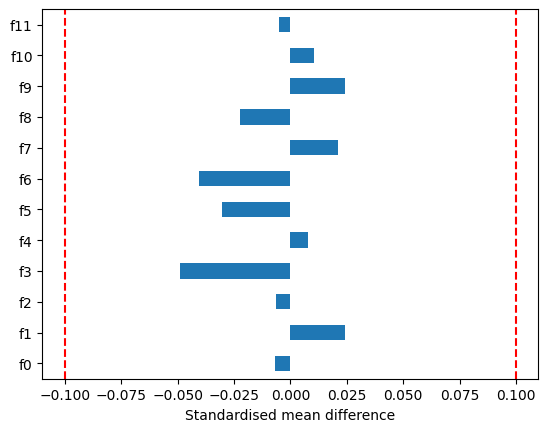

In [7]:
smd.plot.barh()
plt.axvline(0.1, color="red", linestyle="--")
plt.axvline(-0.1, color="red", linestyle="--")
plt.xlabel("Standardised mean difference")
plt.show()

The groups are balanced: no feature has an SMD above 0.1 (the largest is f3 at -0.049). With about 14 million users, a significance test would still flag these differences, because large samples can detect very small differences. That doesn't make them important, so I use SMD to judge their size. They could come from pooling several experiments or from the non-uniform sub-sampling, but the data has no experiment ID, so I can't confirm the cause.


## Step 2: Treatment effect

For `visit` and for `conversion`, I calculate:

- the rate in each group
- the absolute difference, B minus A (in percentage points)
- the relative difference (in %)

In [8]:
rates = df.groupby("treatment")[OUTCOMES].mean()
rates

,visit,conversion
treatment,,
0,0.038201,0.001938
1,0.048543,0.003089


In [9]:
abs_diff_visit = rates.loc[1, "visit"] - rates.loc[0, "visit"]
print (abs_diff_visit * 100)
rel_diff_visit = abs_diff_visit /  rates.loc[0, "visit"]
print (rel_diff_visit * 100)

1.0342403129198283
27.073675539019614


In [10]:
abs_diff_conv = rates.loc[1, "conversion"] - rates.loc[0, "conversion"]
print (abs_diff_conv * 100)
rel_diff_conv = abs_diff_conv /  rates.loc[0, "conversion"]
print (rel_diff_conv * 100)

0.11518730521316278
59.4488117725262


**Result:** Being eligible for ads increased visits from 3.82% to 4.85% (+1.03 percentage points, +27.1%) and conversions from 0.19% to 0.31% (+0.115 percentage points, +59.4%). Conversion has the larger relative effect only because its starting rate is so low. In absolute terms, the visit effect is about 9 times larger.

## Step 3: Significance and confidence intervals

**Null Hypothesis** : being eligible for ads has no effect, so the treated and control groups have the same rate.




In [11]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

n_treated = (df["treatment"] == 1).sum()
n_control = (df["treatment"] == 0).sum()

visits_treated = df.loc[df["treatment"] == 1, "visit"].sum()
visits_control = df.loc[df["treatment"] == 0, "visit"].sum()

z, p = proportions_ztest(
    [visits_treated, visits_control],
    [n_treated, n_control],
)

low, high = confint_proportions_2indep(
    visits_treated, n_treated,
    visits_control, n_control,
)

print(f"z = {z:.1f}, p = {p:.3g}")
print(f"95% CI: {low * 100:.3f} to {high * 100:.3f} percentage points")


z = 65.2, p = 0
95% CI: 1.005 to 1.063 percentage points


In [12]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

n_treated = (df["treatment"] == 1).sum()
n_control = (df["treatment"] == 0).sum()

conversions_treated = df.loc[df["treatment"] == 1, "conversion"].sum()
conversions_control = df.loc[df["treatment"] == 0, "conversion"].sum()

z, p = proportions_ztest(
    [conversions_treated, conversions_control],
    [n_treated, n_control],
)

low, high = confint_proportions_2indep(
    conversions_treated, n_treated,
    conversions_control, n_control,
)

print(f"z = {z:.1f}, p = {p:.3g}")
print(f"95% CI: {low * 100:.3f} to {high * 100:.3f} percentage points")


z = 28.5, p = 7.31e-179
95% CI: 0.108 to 0.122 percentage points


**Result:**

- **Visits:** the effect is statistically significant (z = 65.2, p < 0.001). The true increase is plausibly between 1.005 and 1.063 percentage points.
- **Conversions:** the effect is statistically significant (z = 28.5, p < 0.001). The true increase is plausibly between 0.108 and 0.122 percentage points.

Neither interval includes 0, which agrees with the significant results. The intervals only cover random noise. They don't cover any bias from pooling several experiments, which I can't check without an experiment ID.

**What the p-value means:** if the null hypothesis were true, the p-value is the probability of seeing a difference at least this large by random chance. It is not the probability that the result is due to chance, and it does not tell me how big the effect is.

## Step 4: Is it big enough to matter?

Statistical significance is not the same as practical impact. Treated users had a chance of seeing ads, but not all of them did.


In [13]:
per_million = 1_000_000

print(f"Extra visits per 1M: {abs_diff_visit * per_million:,.0f}")
print(f"Extra conversions per 1M: {abs_diff_conv * per_million:,.0f}")

exposure_rate = df.loc[df["treatment"] == 1, "exposure"].mean()
print(f"Treated users who saw an ad: {exposure_rate * 100:.1f}%")


Extra visits per 1M: 10,342
Extra conversions per 1M: 1,152
Treated users who saw an ad: 3.6%


**Who it applies to:** The effect is an intention-to-treat estimate. It averages over everyone eligible for ads, although only 3.6% of them saw one, so the effect on those who saw an ad is probably much larger.

**At scale:** Per 1 million users made eligible for ads, I estimate about 10,342 extra visits (95% CI: 10,055 to 10,628) and about 1,152 extra conversions (95% CI: 1,084 to 1,219).

**Worth the money?** The data doesn't say. I'd need the ad cost and the value of one conversion to calculate ROI.

## Step 5: Power calculation

Suppose a team wants to run a new test with a 50/50 split, alpha = 0.05 and power = 0.8.

- How many users per group would it need to detect the conversion effect you measured?
- How does that number change for a visit effect, and for a conversion effect half this size?




In [14]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

def users_per_group(control_rate, treated_rate):
    effect = proportion_effectsize(treated_rate, control_rate)
    return NormalIndPower().solve_power(
        effect_size=effect,
        alpha=0.05,
        power=0.8,
        ratio=1,
    )

conv_control = rates.loc[0, "conversion"]
visit_control = rates.loc[0, "visit"]

n_conv = users_per_group(conv_control, conv_control + abs_diff_conv)
n_visit = users_per_group(visit_control, visit_control + abs_diff_visit)
n_conv_half = users_per_group(conv_control, conv_control + abs_diff_conv / 2)

print(f"Conversion effect: {n_conv:,.0f}")
print(f"Visit effect: {n_visit:,.0f}")
print(f"Half the conversion effect: {n_conv_half:,.0f}")


Conversion effect: 29,269
Visit effect: 6,068
Half the conversion effect: 104,648


Result: With a 50/50 split, alpha = 0.05 and power = 0.8, a new test would need about 29,000 users per group to detect the conversion effect, and about 6,100 for the visit effect. Conversion needs more users because its effect is much smaller in absolute terms. Detecting half the conversion effect would need about 105,000 users per group, 3.6 times more, because required users grow roughly with the square of the effect reduction. These numbers assume the true effect is as large as the one measured here. A real test should instead plan around the smallest effect worth detecting

## Step 6: Segments

Split users into 5 groups by one feature  and calculate the effect per group. 
- Why will some segments look significant by chance?
- Apply a correction (`statsmodels.stats.multitest.multipletests`). What changes?



In [16]:
from statsmodels.stats.multitest import multipletests

SEGMENT_FEATURES = ["f0", "f2", "f6", "f8", "f9"]

def segment_effects(feature, outcome="conversion", bins=5):
    segment = pd.qcut(df[feature], q=bins, duplicates="drop")
    rows = []
    for name, group in df.groupby(segment, observed=True):
        treated = group.loc[group["treatment"] == 1, outcome]
        control = group.loc[group["treatment"] == 0, outcome]
        z, p = proportions_ztest(
            [treated.sum(), control.sum()],
            [len(treated), len(control)],
        )
        rows.append({
            "feature": feature,
            "segment": str(name),
            "users": len(group),
            "treated_share": group["treatment"].mean(),
            "effect_pp": (treated.mean() - control.mean()) * 100,
            "p_value": p,
        })
    return pd.DataFrame(rows)

segments = pd.concat(
    [segment_effects(f) for f in SEGMENT_FEATURES],
    ignore_index=True,
)
segments["p_adjusted"] = multipletests(segments["p_value"], method="fdr_bh")[1]
segments["extra_conversions"] = segments["users"] * segments["effect_pp"] / 100

segments.sort_values("effect_pp", ascending=False)


,feature,segment,users,treated_share,effect_pp,p_value,p_adjusted,extra_conversions
15,f9,"(16.226, 75.295]",2411445,0.854937,0.544585,2.746416e-132,1.464755e-131,13132.377278
11,f8,"(3.634, 3.893]",2848806,0.855120,0.482101,1.148111e-138,9.184891e-138,13734.120658
7,f6,"(-31.431, -7.822]",2906669,0.857732,0.383986,1.338794e-131,5.355175e-131,11161.212685
0,f0,"(12.615, 18.127]",5591837,0.851375,0.231140,1.370616e-150,2.192986e-149,12924.960594
5,f2,"(8.382, 8.815]",2795932,0.851211,0.173938,3.054551e-58,8.145469e-58,4863.177327
4,f2,"(8.213000000000001, 8.382]",8387755,0.850357,0.125807,6.605314e-114,2.113701e-113,10552.406219
1,f0,"(18.127, 22.771]",2795921,0.850146,0.080623,4.465529e-24,8.931058e-24,2254.149411
8,f6,"(-7.822, -3.994]",3104117,0.849725,0.061879,1.352441e-21,2.404339e-21,1920.809049
10,f6,"(-1.288, 0.294]",3705545,0.845695,0.038131,4.465154e-10,6.494769e-10,1412.976812
12,f8,"(3.893, 3.944]",2871462,0.847663,0.031038,4.049317e-12,6.478907e-12,891.243623


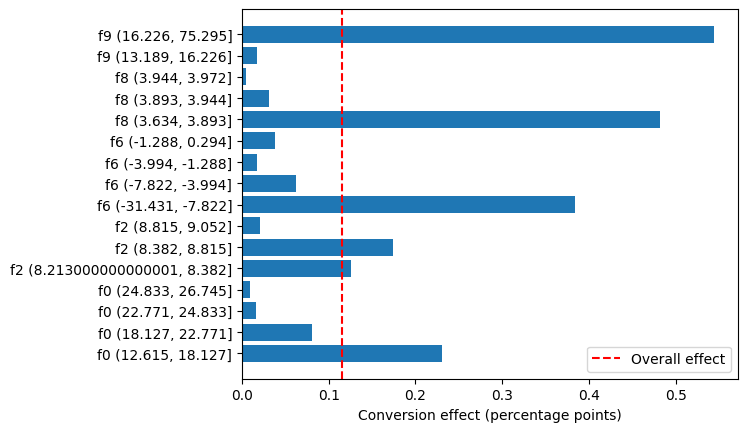

In [17]:
labels = segments["feature"] + " " + segments["segment"]
plt.barh(labels, segments["effect_pp"])
plt.axvline(abs_diff_conv * 100, color="red", linestyle="--", label="Overall effect")
plt.xlabel("Conversion effect (percentage points)")
plt.legend()
plt.show()



Result: The effect varies strongly between segments, from +0.005 to +0.545 percentage points. The top f9 segment holds about 17% of users but about 87% of that feature's extra conversions. All 16 segments stay significant after Benjamini-Hochberg correction. I used 5 features because the other 7 are dominated by one repeated value and don't split into groups. This is exploratory: the segments were chosen after seeing the data and the features are anonymised, so a new test should confirm the result before anyone acts on it.



## Conclusion

Being eligible for ads increased conversions from 0.19% to 0.31%, or about 1,150 extra conversions per 1 million users (95% CI: 1,084 to 1,219). The effect is very unlikely to be random noise, but this data has no costs or revenue, so I can't say whether it was profitable. Most of the extra conversions come from a small share of users, so better targeting could be valuable, and a new test should confirm that. The data pools several experiments without an experiment ID, so I can't rule out some bias from pooling.

